# VEDU executed LOCAL analysis
20 training runs, 2 datasets, 2 temporal protocols, 5 seeds. Training ran via benchmark.py; this notebook audits and displays its saved outputs. No Kaggle execution is claimed.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
results = pd.read_csv(ROOT / "model-results.csv")
assert len(results) == 160
print("Environment: local CPU; completed model rows:", len(results))
display(pd.read_csv(ROOT / "model-summary.csv", header=[0,1], index_col=[0,1,2]))

Environment: local CPU; completed model rows: 160


Recall@3  \
                                                                           mean   
dataset            protocol          model                                        
kaggle_logs        global_temporal   BPR+GRU without HUSPM (ablation)  0.553691   
                                     BPR-MF                            0.604027   
                                     GRU-next-item                     0.533557   
                                     HUSPM-only                        0.604027   
                                     Hybrid BPR+GRU+HUSPM              0.553691   
                                     Item-KNN (sklearn external)       0.600671   
                                     Popularity (train-only)           0.610738   
                                     Random (seeded)                   0.611409   
                   per_user_temporal BPR+GRU without HUSPM (ablation)  0.606000   
                                     BPR-MF                            0.581333   
                                     GRU-next-item                     0.600667   
                                     HUSPM-only                        0.630000   
                                     Hybrid BPR+GRU+HUSPM              0.613333   
                                     Item-KNN (sklearn external)       0.556667   
                                     Popularity (train-only)           0.636667   
                                     Random (seeded)                   0.605333   
kaggle_recommender global_temporal   BPR+GRU without HUSPM (ablation)  0.104762   
                                     BPR-MF                            0.123810   
                                     GRU-next-item                     0.071429   
                                     HUSPM-only                        0.023810   
                                     Hybrid BPR+GRU+HUSPM              0.104762   
                                     Item-KNN (sklearn external)       0.047619   
                                     Popularity (train-only)           0.023810   
                                     Random (seeded)                   0.000000   
                   per_user_temporal BPR+GRU without HUSPM (ablation)  0.398673   
                                     BPR-MF                            0.151469   
                                     GRU-next-item                     0.398673   
                                     HUSPM-only                        0.027488   
                                     Hybrid BPR+GRU+HUSPM              0.398673   
                                     Item-KNN (sklearn external)       0.157346   
                                     Popularity (train-only)           0.041706   
                                     Random (seeded)                   0.003412   

                                                                                 \
                                                                            std   
dataset            protocol          model                                        
kaggle_logs        global_temporal   BPR+GRU without HUSPM (ablation)  0.027570   
                                     BPR-MF                            0.011130   
                                     GRU-next-item                     0.014038   
                                     HUSPM-only                        0.000000   
                                     Hybrid BPR+GRU+HUSPM              0.027570   
                                     Item-KNN (sklearn external)       0.000000   
                                     Popularity (train-only)           0.000000   
                                     Random (seeded)                   0.039663   
                   per_user_temporal BPR+GRU without HUSPM (ablation)  0.020467   
                                     BPR-MF                            0.013250   
                                     GRU-next-item                     0.018166   
   

In [2]:
display(pd.read_csv(ROOT / "huspm-ablation.csv"))
audit = json.loads((ROOT / "validation.json").read_text())
print("Artifact reload and per-user rank checks:", audit["completed_runs"])
print("Zero HUSPM weight runs:", audit["hybrid_huspm_weight_zero_runs"])
print("\n".join(audit["limitations"]))

,dataset,protocol,seed,huspm_weight_hybrid,delta_NDCG@3,delta_Recall@3
0,kaggle_logs,global_temporal,13,0.0,0.000000,0.000000
1,kaggle_logs,global_temporal,21,0.0,0.000000,0.000000
2,kaggle_logs,global_temporal,42,0.0,0.000000,0.000000
3,kaggle_logs,global_temporal,77,0.0,0.000000,0.000000
4,kaggle_logs,global_temporal,101,0.0,0.000000,0.000000
5,kaggle_logs,per_user_temporal,13,0.0,0.000000,0.000000
6,kaggle_logs,per_user_temporal,21,0.2,0.013254,0.036667
7,kaggle_logs,per_user_temporal,42,0.0,0.000000,0.000000
8,kaggle_logs,per_user_temporal,77,0.0,0.000000,0.000000
9,kaggle_logs,per_user_temporal,101,0.0,0.000000,0.000000


Artifact reload and per-user rank checks: 20
Zero HUSPM weight runs: 19
Kaggle-hosted data does not by itself establish real learner provenance.
The small module catalog makes Random Recall@3 intrinsically high.
Recall/NDCG measure next-item ranking, not learning gains or curriculum validity.
Per-user temporal is a warm-history diagnostic; global temporal is the deployment protocol.
Five seeds quantify initialization variance, not five independent datasets.
No test-set tuning; zero HUSPM weights and negative ablation deltas must be reported.
A local result is not evidence of execution on Kaggle.


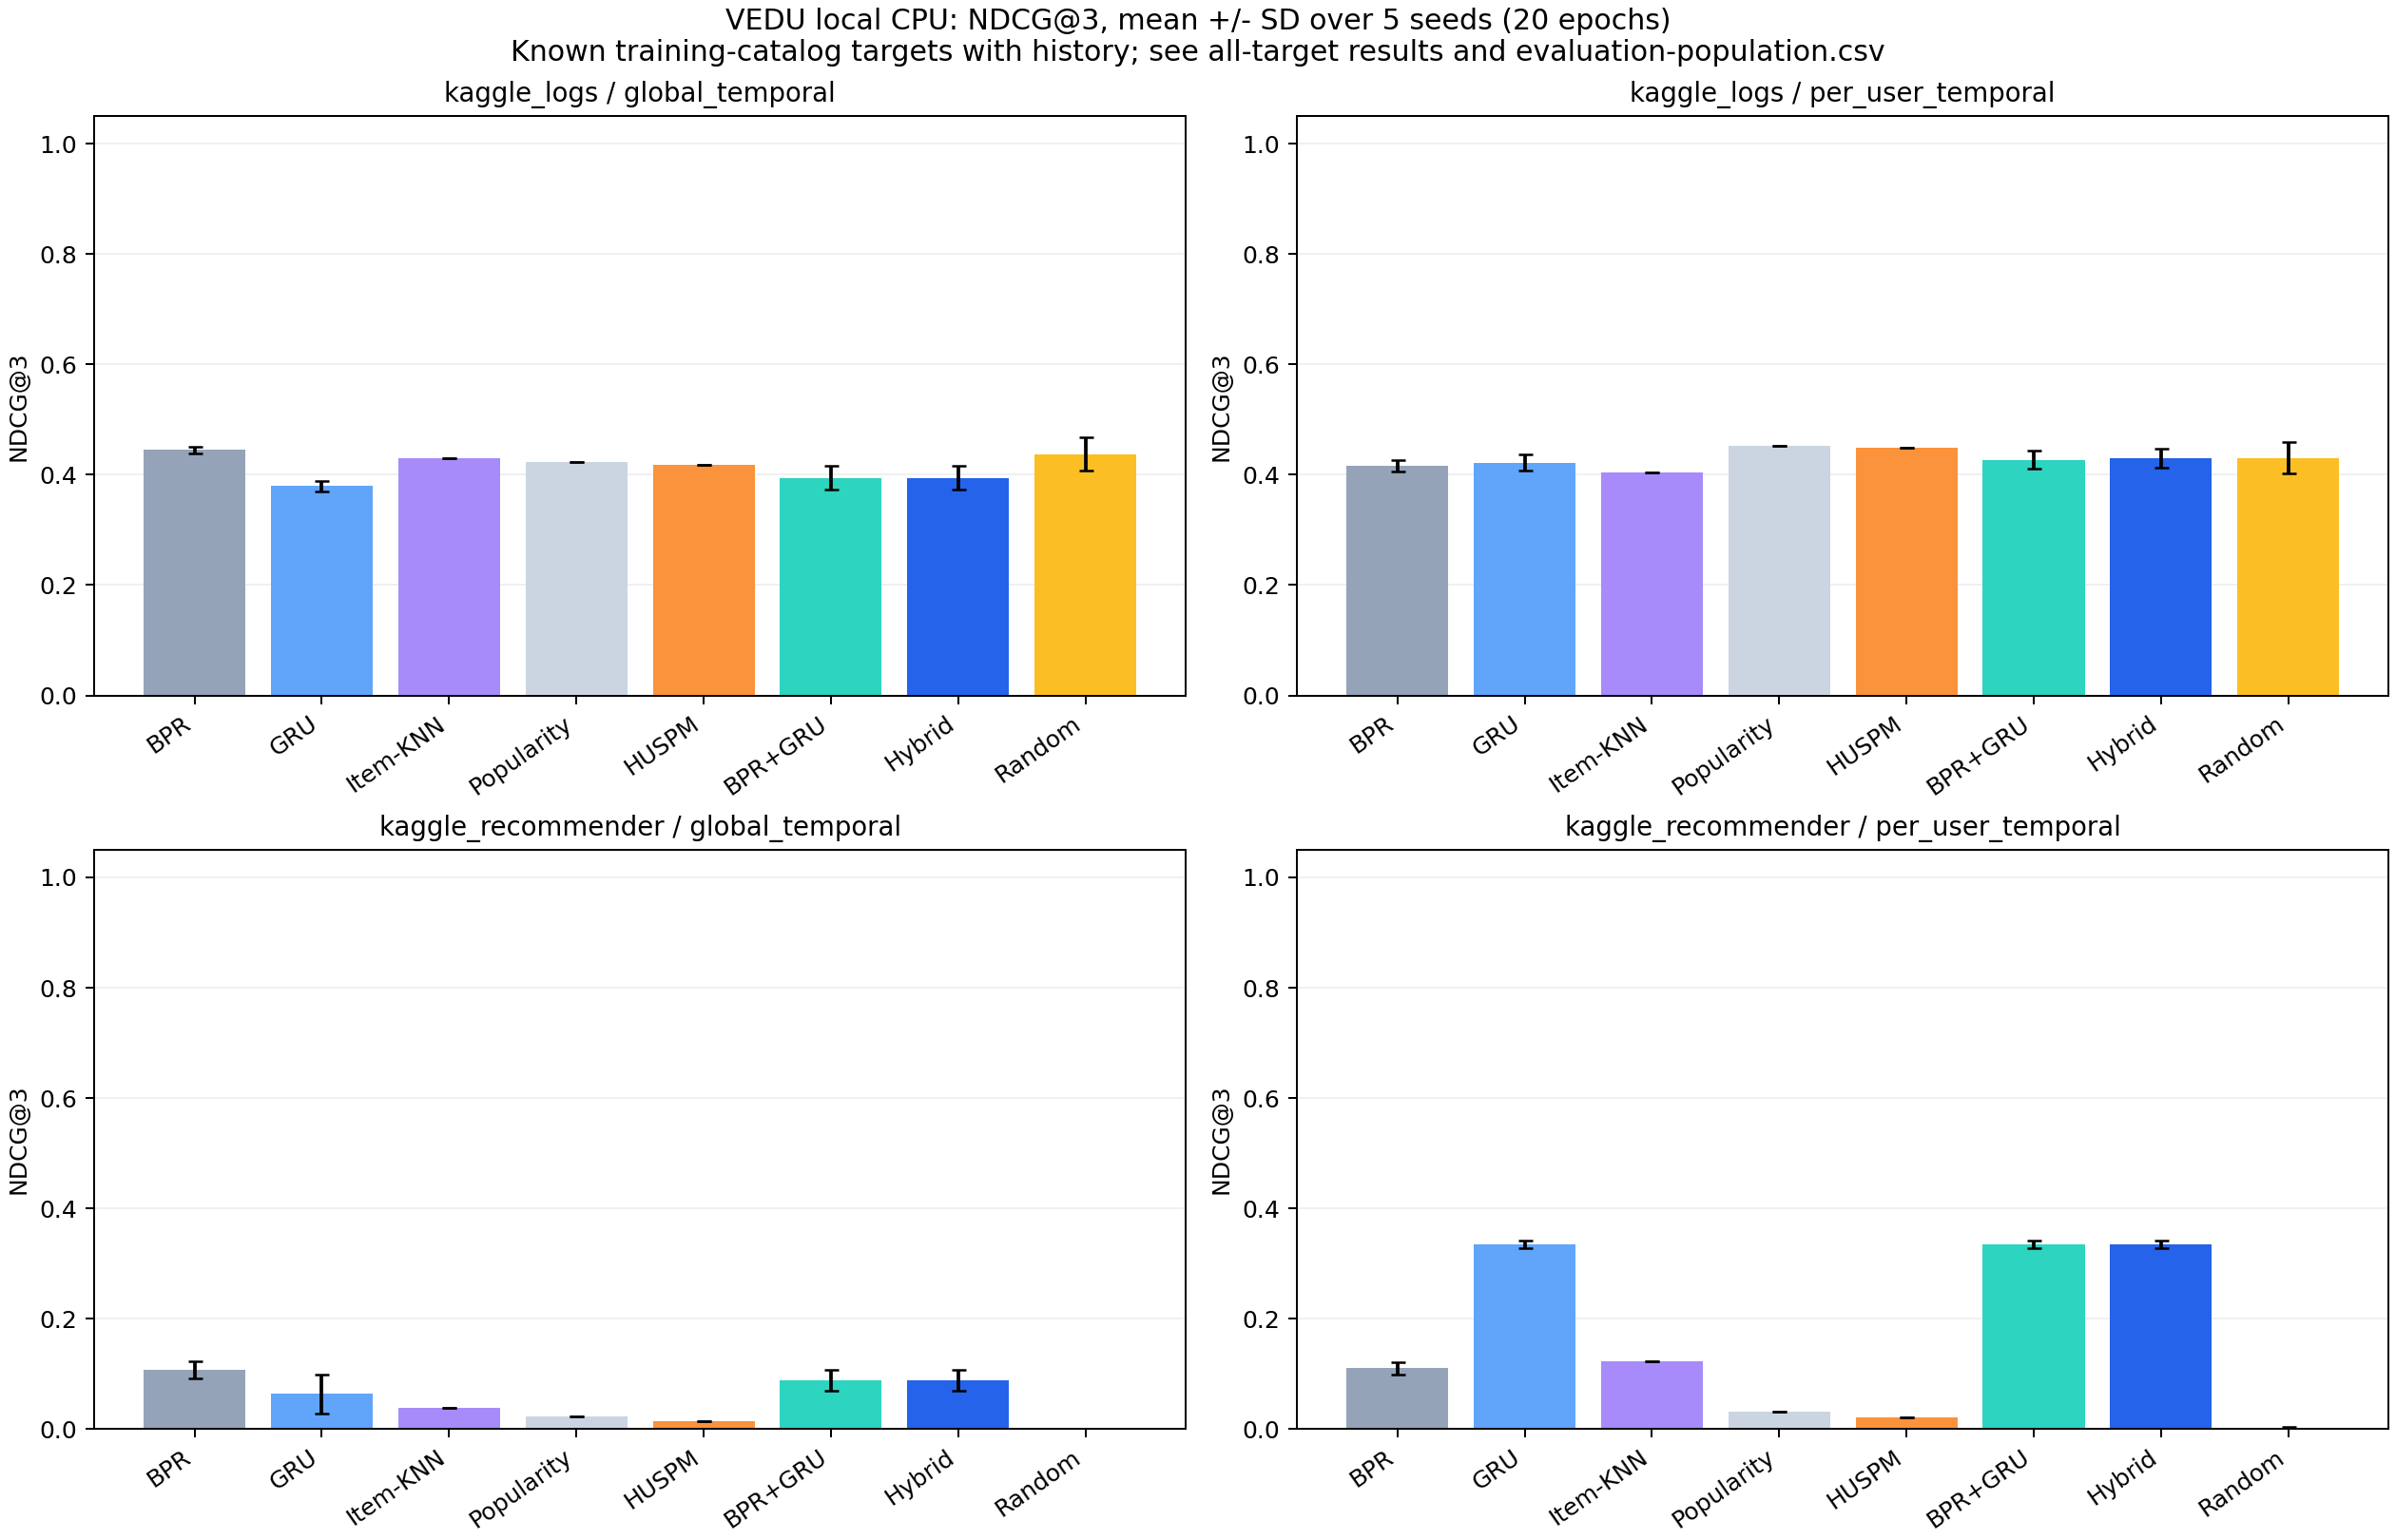

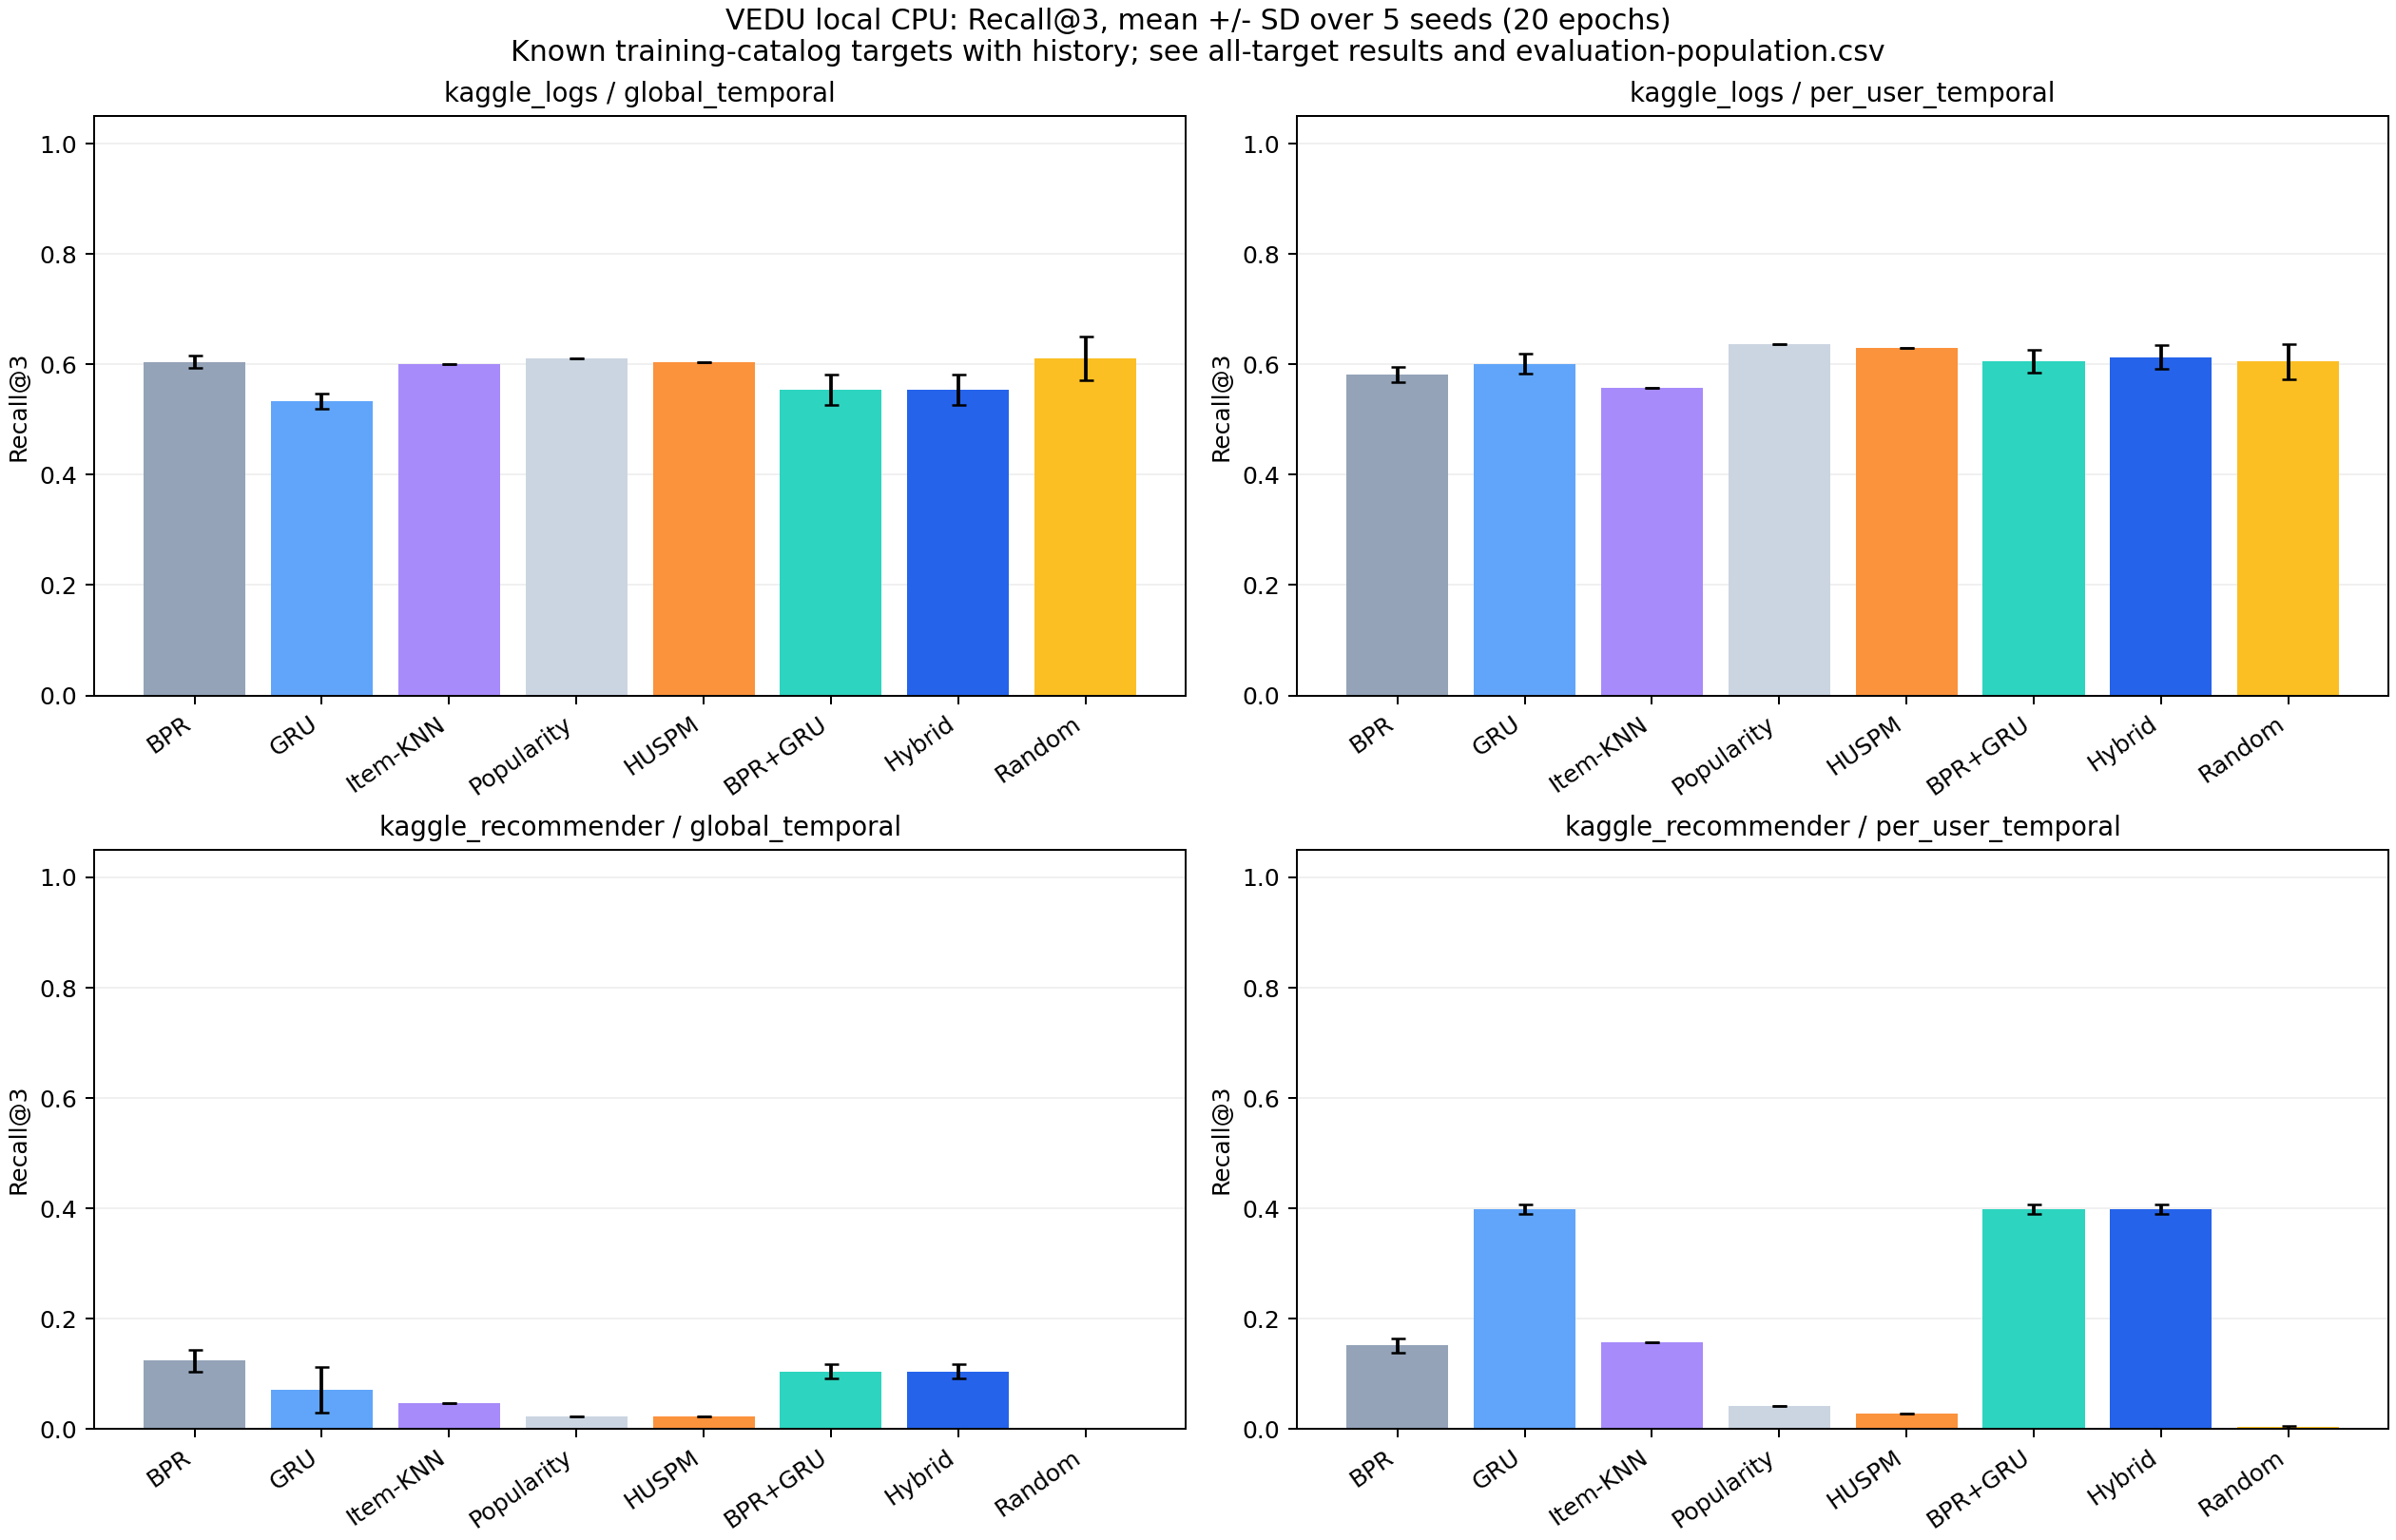

In [3]:
display(Image(filename=str(ROOT / "ndcg-at-3.png")))
display(Image(filename=str(ROOT / "recall-at-3.png")))